In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris()
dane = iris.data

In [8]:
tabela = pd.DataFrame(iris.data, columns=iris.feature_names)
tabela['gatunek'] = pd.Categorical.from_codes(iris.target, iris.target_names)

display(tabela.head(10))

print("Liczba wierszy i kolumn (wymiary):", tabela.shape)
print("\nPodział na klasy (ile jest kwiatów danego gatunku):")
print(tabela['gatunek'].value_counts())
print("\nPodstawowe statystyki (minimum, maksimum, średnia dla cech):")
print(tabela.describe())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),gatunek
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


Liczba wierszy i kolumn (wymiary): (150, 5)

Podział na klasy (ile jest kwiatów danego gatunku):
gatunek
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Podstawowe statystyki (minimum, maksimum, średnia dla cech):
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%           

In [4]:
minimum = np.min(dane, axis=0)
maksimum = np.max(dane, axis=0)

dane_znormalizowane = (dane - minimum) / (maksimum - minimum)

In [5]:
liczba_neuronow = 3
liczba_cech = 4

wagi = np.random.rand(liczba_neuronow, liczba_cech)

In [6]:
epoki = 100
wspolczynnik_uczenia = 0.1

for epoka in range(epoki):
    for wektor_kwiatu in dane_znormalizowane:

        # 1. Obliczanie odległości euklidesowej kwiatu od każdego z 3 neuronów
        odleglosci = np.sqrt(np.sum((wagi - wektor_kwiatu)**2, axis=1))

        # 2. Wybór zwycięzcy (BMU)
        zwyciezca_index = np.argmin(odleglosci)

        # 3. Aktualizacja wag tylko dla zwycięskiego neuronu
        # nowe_wagi = stare_wagi + wspolczynnik * (dane - stare_wagi)
        wagi[zwyciezca_index] = wagi[zwyciezca_index] + wspolczynnik_uczenia * (wektor_kwiatu - wagi[zwyciezca_index])


    wspolczynnik_uczenia = wspolczynnik_uczenia * 0.95

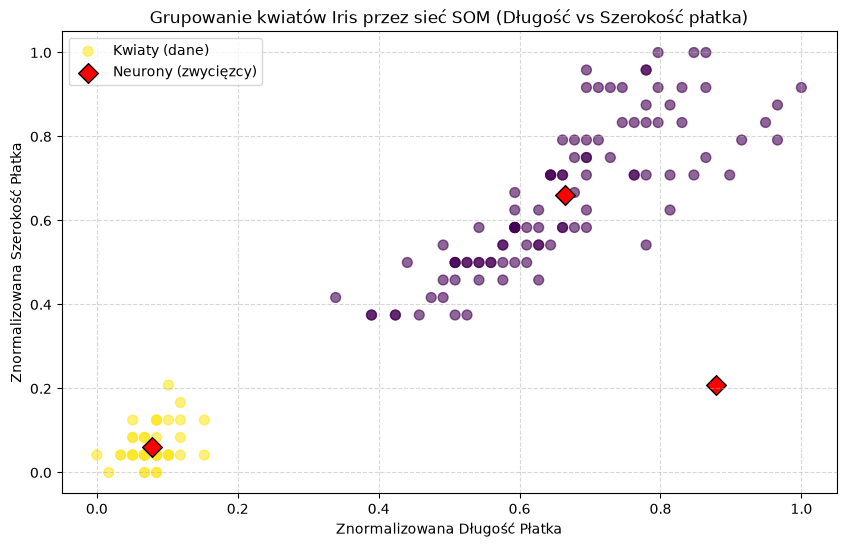

In [7]:
zwyciezcy = []

for wektor_kwiatu in dane_znormalizowane:
    odleglosci = np.sqrt(np.sum((wagi - wektor_kwiatu)**2, axis=1))
    zwyciezca_index = np.argmin(odleglosci)
    zwyciezcy.append(zwyciezca_index)

zwyciezcy = np.array(zwyciezcy)


plt.figure(figsize=(10, 6))

# 2 długość płatka, 3 szerokość płatka
cecha_x = 2
cecha_y = 3


#Kropki w zależności od przypisanego neuronu
plt.scatter(
    dane_znormalizowane[:, cecha_x],
    dane_znormalizowane[:, cecha_y],
    c=zwyciezcy,
    cmap='viridis',
    s=50,
    alpha=0.6,
    label='Kwiaty (dane)'
)


plt.scatter(
    wagi[:, cecha_x],
    wagi[:, cecha_y],
    c='red',
    marker='D',
    s=100,
    edgecolor='black',
    label='Neurony (zwycięzcy)'
)

plt.title('Grupowanie kwiatów Iris przez sieć SOM (Długość vs Szerokość płatka)')
plt.xlabel('Znormalizowana Długość Płatka')
plt.ylabel('Znormalizowana Szerokość Płatka')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()